# 02 — Main analysis: reproduce the frozen headline result

Re-runs, from data committed in this repository (no credentials, no network):

1. **Integrity**: every committed frozen result file is byte-identical to the freeze snapshot, and the preregistered plan text still hashes to `40d1e7dc…ca8a32`.
2. **Primary comparison (Mahajanga, Madagascar)**: logistic regression A (conventional Sentinel-2 + context) vs C (A + full EMIT hyperspectral), spatial out-of-fold PR-AUC, paired spatial-block bootstrap (1,000 draws).
3. **Spectral control**: C vs D (EMIT convolved to Sentinel-2 bands).
4. **Saudi Red Sea EXTERNAL_TEST**: Madagascar-trained LR/RF A, C, D, F applied to EMIT scene `EMIT_L2A_RFL_001_20230330T094159_2308907_012`.

Each statistic is compared with the frozen value (`reproducibility/expected_headline.json`) within ±0.002 (LR C uses randomized PCA; tiny floating-point differences across BLAS builds are expected). Runtime about 2 minutes.

In [1]:
import sys, time
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / 'reproduce.py').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import pandas as pd
import reproduce

start = time.time()
print('Repository root:', ROOT.name)

Repository root: mangrove-early-warning-813


In [2]:
from pathlib import Path
import rasterio

SAMPLES = ROOT / "data/sample_input"
cohort = pd.read_parquet(SAMPLES / "model_cohort.parquet")
saudi = pd.read_parquet(SAMPLES / "saudi_binary_cohort.parquet")
with rasterio.open(SAMPLES / "example_emit_clip.tif") as clip:
    clip_shape = (clip.count, clip.height, clip.width)
assert len(cohort) == 2220 and len(saudi) == 843 and clip_shape[0] == 229
print(f"Sample inputs: {len(cohort):,} Mahajanga pixels; {len(saudi):,} Saudi pixels; EMIT clip {clip_shape}")


Sample inputs: 2,220 Mahajanga pixels; 843 Saudi pixels; EMIT clip (229, 64, 64)


In [3]:
integrity = pd.DataFrame(reproduce.integrity())
integrity

,quantity,reproduced,frozen,abs_difference,status
0,required public reproduction files present,6,6,0,PASS


In [4]:
headline = pd.DataFrame(reproduce.level1())
pd.set_option('display.max_rows', 200)
headline

Refitted Madagascar LR A


Refitted Madagascar LR C


Refitted Madagascar LR D


,quantity,reproduced,frozen,abs_difference,status
0,Madagascar LR A PR-AUC,0.2675,0.2675,5.551115e-17,PASS
1,Madagascar LR C PR-AUC,0.2743,0.2742,1.002356e-04,PASS
2,Madagascar LR D PR-AUC,0.2854,0.2854,0.000000e+00,PASS
3,Madagascar C-A,0.0068,0.0067,1.002356e-04,PASS
4,Madagascar C-A CI low,-0.0366,-0.0366,1.923788e-06,PASS
5,Madagascar C-A CI high,0.0607,0.0606,8.500663e-05,PASS
6,Madagascar C-D,-0.0111,-0.0112,1.002356e-04,PASS
7,Madagascar C-D CI low,-0.0415,-0.0415,3.998531e-07,PASS
8,Madagascar C-D CI high,0.0280,0.0280,3.746475e-05,PASS


In [5]:
summary = headline[headline.quantity.str.startswith('Madagascar')][['quantity', 'reproduced', 'frozen', 'status']]
summary

,quantity,reproduced,frozen,status
0,Madagascar LR A PR-AUC,0.2675,0.2675,PASS
1,Madagascar LR C PR-AUC,0.2743,0.2742,PASS
2,Madagascar LR D PR-AUC,0.2854,0.2854,PASS
3,Madagascar C-A,0.0068,0.0067,PASS
4,Madagascar C-A CI low,-0.0366,-0.0366,PASS
5,Madagascar C-A CI high,0.0607,0.0606,PASS
6,Madagascar C-D,-0.0111,-0.0112,PASS
7,Madagascar C-D CI low,-0.0415,-0.0415,PASS
8,Madagascar C-D CI high,0.0280,0.0280,PASS


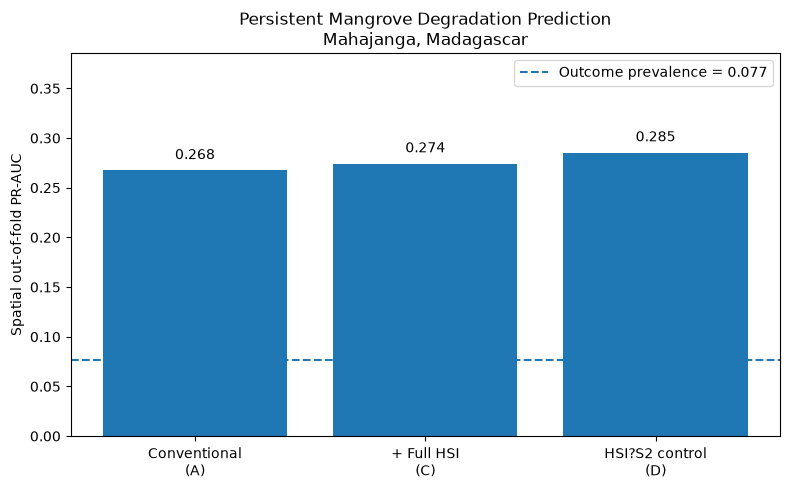

Saved: results\example_output.png


In [6]:
import matplotlib.pyplot as plt

plot_rows = headline[
    headline["quantity"].isin([
        "Madagascar LR A PR-AUC",
        "Madagascar LR C PR-AUC",
        "Madagascar LR D PR-AUC",
    ])
].copy()

labels = ["Conventional\n(A)", "+ Full HSI\n(C)", "HSI?S2 control\n(D)"]
values = plot_rows["reproduced"].to_numpy()

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(labels, values)

ax.axhline(0.077, linestyle="--", linewidth=1.5, label="Outcome prevalence = 0.077")
ax.set_ylabel("Spatial out-of-fold PR-AUC")
ax.set_ylim(0, max(values) * 1.35)
ax.set_title("Persistent Mangrove Degradation Prediction\nMahajanga, Madagascar")

for bar, value in zip(bars, values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.008,
        f"{value:.3f}",
        ha="center",
        va="bottom",
    )

ax.legend()
fig.tight_layout()

output = ROOT / "results/example_output.png"
fig.savefig(output, dpi=160, bbox_inches="tight")
plt.show()

print("Saved:", output.relative_to(ROOT))


In [7]:
checks = pd.concat([integrity, headline], ignore_index=True)
passed = bool((checks.status == 'PASS').all())
print(f"{(checks.status == 'PASS').sum()}/{len(checks)} checks passed in {time.time() - start:.0f} s")
print('HEADLINE CHECK:', 'PASS' if passed else 'FAIL')
assert passed, checks[checks.status != 'PASS']

10/10 checks passed in 20 s
HEADLINE CHECK: PASS
